In [1]:
pip install catboost xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 74.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 62.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.6/206.6 MB 22.5 MB/s  0:00:09
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [catboost]


In [2]:
import pandas as pd
import numpy as np
import joblib
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report)
from google.colab import drive

# Carga del dataset
drive.mount('/content/drive')

path = '/content/drive/MyDrive/MachineLearningCVE/Data'
df_IDS = pd.read_csv(path + '/dataset_limpio.csv')
le = joblib.load(path + '/Modelos/label_encoder.pkl')

X = df_IDS.drop(columns=['label'])
y_enc = le.transform(df_IDS['label'])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Carga de los modelos
archivos = {"RandomForest": "random_forest", "XGBoost": "xgboost", "CatBoost": "catboost"}
modelos = {n: joblib.load(path + f'/Modelos/{a}.pkl') for n, a in archivos.items()}

# Se carga el entrenamiento guardado durante la creación del Modelo
id_test = np.load(path + '/Modelos/id_test.npy')
X_test = X.loc[id_test]
y_test = y_enc[id_test]

In [4]:
# Tabla comparativa de metricas
import json

# Importacion de los tiempos de entrenamiento
with open(path + '/Modelos/tiempos.json') as f:
  tiempos = json.load(f)

filas = []

for nombre, modelo in modelos.items():
    y_pred = modelo.predict(X_test)
    filas.append({
      "Modelo": nombre,
      "Accuracy": round(accuracy_score(y_test, y_pred), 4),
      "Precision": round(precision_score(y_test, y_pred, average='macro'), 4),
      "Recall": round(recall_score(y_test, y_pred, average='macro'), 4),
      "F1 Score": round(f1_score(y_test, y_pred, average='macro'), 4),
      "Tiempo(s)": tiempos[nombre]

    })

df_comparativa = pd.DataFrame(filas)
print(df_comparativa.to_string(index=False))
df_comparativa.to_csv(path + '/DatosEstadisticos/comparativa_modelos.csv', index=False)


      Modelo  Accuracy  Precision  Recall  F1 Score  Tiempo(s)
RandomForest    0.9986     0.9832  0.9638    0.9729     933.88
     XGBoost    0.9991     0.9827  0.9618    0.9710     327.70
    CatBoost    0.9990     0.9814  0.9585    0.9686     362.98


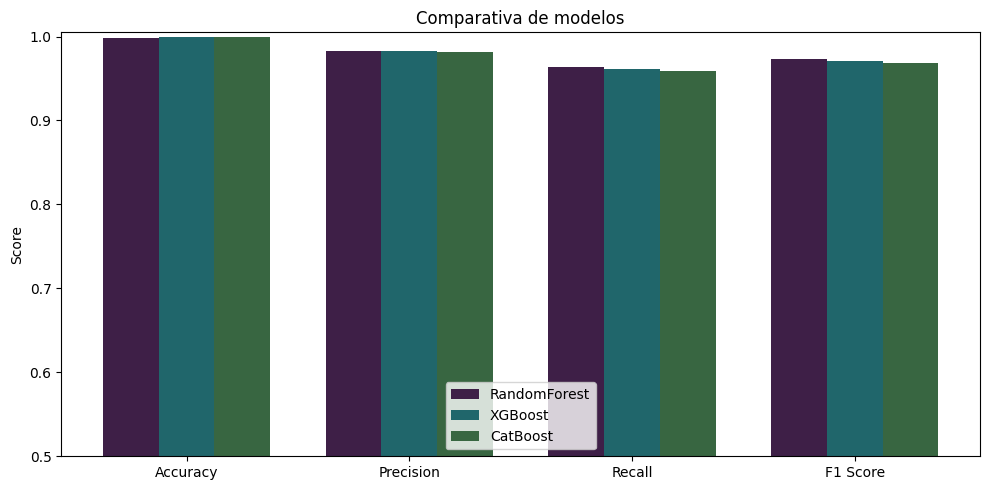

In [6]:
# Grafica de la comparativa
import matplotlib.pyplot as plt

metricas = ["Accuracy", "Precision", "Recall", "F1 Score"]
x = np.arange(len(metricas))
width = 0.25
colores = ["#3E1F47", "#20666B", "#386641"]

fig, ax = plt.subplots(figsize = (10, 5))

for i, (_, fila) in enumerate(df_comparativa.iterrows()):
  valores = [fila[m] for m in metricas]
  ax.bar(x + i * width, valores, width, label=fila['Modelo'], color = colores[i])

ax.set_xticks(x + width)
ax.set_xticklabels(metricas)
ax.set_ylim(0.50, 1.005)
ax.set_ylabel("Score")
ax.set_title("Comparativa de modelos")
ax.legend()

plt.tight_layout()
plt.show()



In [7]:
# Reporte por clase con el mismo test para todos
preds = {n: m.predict(X_test) for n, m in modelos.items()}
for n, p in preds.items():
    print(n)
    print(classification_report(y_test, p, target_names=le.classes_, digits=3))

RandomForest
              precision    recall  f1-score   support

     Benigno      0.999     0.999     0.999    419269
         Bot      0.908     0.787     0.843       390
 Brute Force      1.000     0.999     1.000      1830
        DDoS      1.000     1.000     1.000     25603
         DoS      0.998     0.998     0.998     38750
    PortScan      0.989     0.989     0.989     18164
  Web Attack      0.988     0.974     0.981       429

    accuracy                          0.999    504435
   macro avg      0.983     0.964     0.973    504435
weighted avg      0.999     0.999     0.999    504435

XGBoost
              precision    recall  f1-score   support

     Benigno      1.000     0.999     0.999    419269
         Bot      0.918     0.749     0.825       390
 Brute Force      1.000     1.000     1.000      1830
        DDoS      1.000     1.000     1.000     25603
         DoS      0.998     1.000     0.999     38750
    PortScan      0.989     0.999     0.994     18164
  W

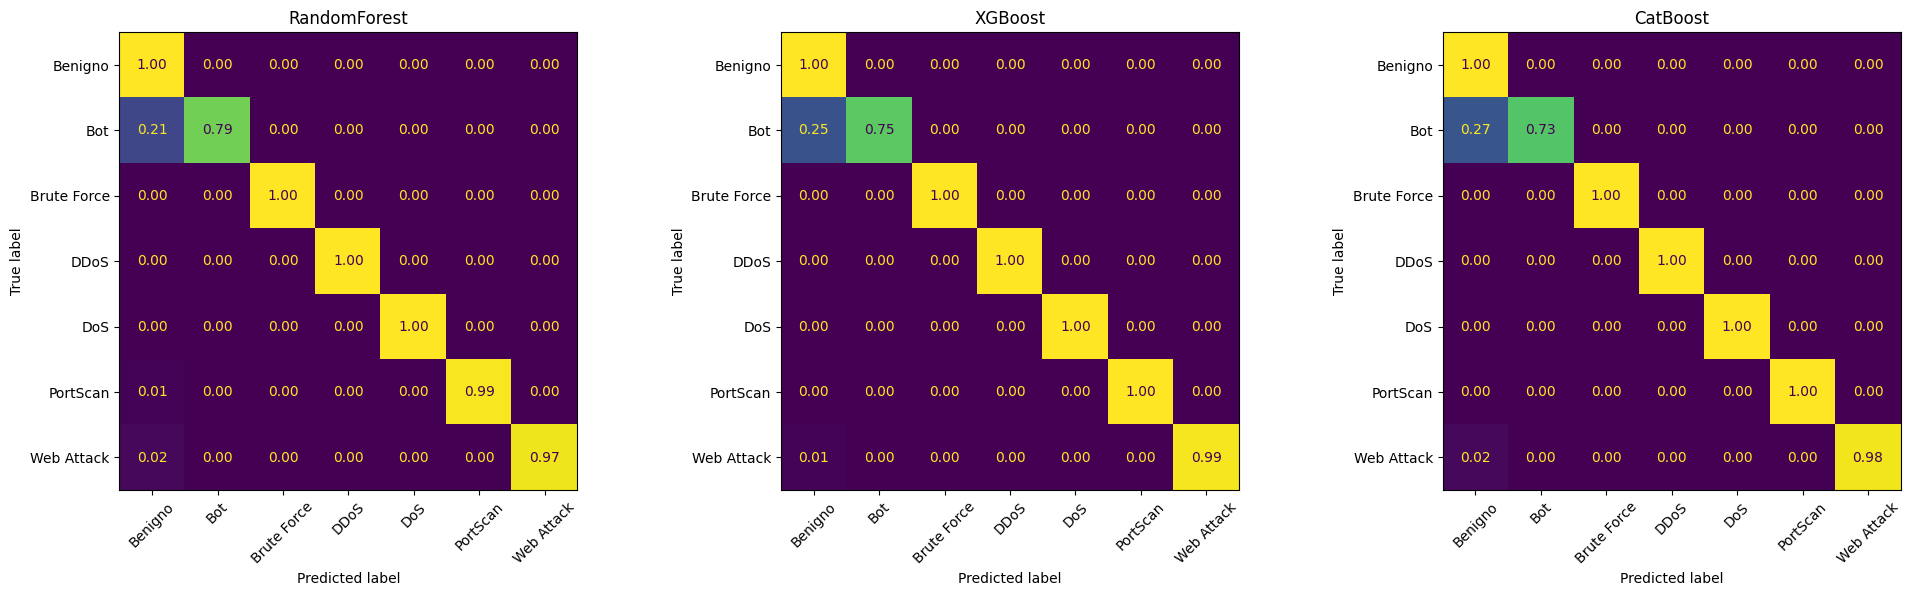

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Matrices normalizadas por fila (recall por clase; con conteos crudos Bot y Web Attack no se ven)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (n, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, p, display_labels=le.classes_, normalize='true',
        values_format='.2f', ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(n)
plt.tight_layout()
plt.show()

In [9]:
# Importancia de features (normalizada para comparar los tres modelos)
imp = pd.DataFrame({n: pd.Series(m.feature_importances_, index=X.columns)
                    for n, m in modelos.items()})
print((imp / imp.sum()).sort_values('CatBoost', ascending=False).head(15).round(3))

                         RandomForest  XGBoost  CatBoost
init_win_bytes_backward         0.030    0.014     0.469
psh_flag_count                  0.018    0.017     0.049
destination_port                0.031    0.010     0.041
packet_length_mean              0.046    0.002     0.040
init_win_bytes_forward          0.017    0.004     0.037
flow_packets_s                  0.026    0.000     0.035
bwd_packet_length_mean          0.093    0.216     0.031
bwd_packet_length_min           0.008    0.005     0.029
bwd_packets_s                   0.022    0.002     0.026
fwd_header_length               0.029    0.005     0.026
act_data_pkt_fwd                0.027    0.074     0.023
flow_bytes_s                    0.013    0.033     0.020
flow_duration                   0.010    0.001     0.018
fwd_packet_length_max           0.048    0.040     0.017
min_seg_size_forward            0.017    0.008     0.016


In [10]:
from sklearn.metrics import confusion_matrix

preds = {n: m.predict(X_test) for n, m in modelos.items()}

def metricas_por_clase(y_true, y_pred, clases):
    cm = confusion_matrix(y_true, y_pred)
    total = cm.sum()
    filas = []
    for i, clase in enumerate(clases):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp
        filas.append({
            "Clase": clase,
            "TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "TPR (recall)": tp / (tp + fn),
            "FNR": fn / (tp + fn),
            "FPR": fp / (fp + tn),
            "TNR": tn / (tn + fp),
            "Precision": tp / (tp + fp) if (tp + fp) > 0 else np.nan,
        })
    return pd.DataFrame(filas)

tablas = []
for nombre, p in preds.items():
    t = metricas_por_clase(y_test, p, le.classes_)
    t.insert(0, "Modelo", nombre)
    tablas.append(t)

df_cls = pd.concat(tablas, ignore_index=True)
print(df_cls.round(4).to_string(index=False))
df_cls.to_csv(path + '/DatosEstadisticos/metricas_por_clase.csv', index=False)

      Modelo       Clase     TP  FN  FP     TN  TPR (recall)    FNR    FPR    TNR  Precision
RandomForest     Benigno 418965 304 377  84789        0.9993 0.0007 0.0044 0.9956     0.9991
RandomForest         Bot    307  83  31 504014        0.7872 0.2128 0.0001 0.9999     0.9083
RandomForest Brute Force   1829   1   0 502605        0.9995 0.0005 0.0000 1.0000     1.0000
RandomForest        DDoS  25601   2   3 478829        0.9999 0.0001 0.0000 1.0000     0.9999
RandomForest         DoS  38660  90  70 465615        0.9977 0.0023 0.0002 0.9998     0.9982
RandomForest    PortScan  17962 202 207 486064        0.9889 0.0111 0.0004 0.9996     0.9886
RandomForest  Web Attack    418  11   5 504001        0.9744 0.0256 0.0000 1.0000     0.9882
     XGBoost     Benigno 418961 308 120  85046        0.9993 0.0007 0.0014 0.9986     0.9997
     XGBoost         Bot    292  98  26 504019        0.7487 0.2513 0.0001 0.9999     0.9182
     XGBoost Brute Force   1830   0   0 502605        1.0000 0.0000 0.